# Phase 9: features (turning squares into numbers)

Classical models (softmax, SVM, MLP) can't look at a picture. They need **numbers that describe it**. This notebook covers all of Phase 9:
- **9.1** one function, `extract(square)` in `ml/features.py`, that turns one 80 × 80 colour square into **1,769 numbers**;
- **9.2** run it on all 240,000 squares, once, and save the result;
- **9.3** check that the numbers actually differ between classes.

**Key idea:** there is **one** feature function, used both in training and in the app. If the two ever prepare a square differently, the app silently gives wrong answers.

| Step | What happens | Numbers out |
|---|---|---|
| 0 | take one 80 × 80 square from the 640 × 400 photo (Phase 6) | 80 × 80 × 3 pixels |
| 1 | colour → **grayscale** | 80 × 80 |
| 2 | resize to **64 × 64** | 64 × 64 |
| 3 | **HOG**: which way the edges run, cell by cell | **1,764** |
| 4 | **5 simple measures**: dark share, edge density, gx share, gy share, contrast | **5** |
| 5 | join them into one row | **1,769** |

### Two different grids (easy to mix up)

1. **8 × 5 grid on the photo** (Phase 6): the 640 × 400 photo is cut into 40 squares of 80 × 80. It decides **which region** we look at, so each square gets its own answer.
2. **8 × 8 grid inside one square** (this phase): the square, resized to 64 × 64, is split into cells of 8 × 8 px. It is how **HOG** looks at the square.

The whole photo is **never** resized to 64 × 64. Only each 80 × 80 square is.

```
photo (any size) -> crop bottom 5/8 -> resize to 640 x 400 -> 8 x 5 grid = 40 squares (80 x 80)
   one square -> grayscale -> resize to 64 x 64 -> 8 x 8 cells -> HOG (1,764) + 5 measures = 1,769 numbers
   ... and the same for the other 39 squares
```

### Settings and where they come from

| Setting | Value | Source |
|---|---|---|
| Resize | 64 × 64 | **Choice:** 64 = 8 HOG cells of 8 px exactly; a bit smaller than 80, so HOG is faster |
| HOG | 9 orientations, 8 × 8 px per cell, 2 × 2 cells per block | **Standard values** from the original HOG paper (Dalal & Triggs, 2005), used by the guide |
| Canny edges | skimage default (sigma = 1) | **Library default** |
| "Much darker" | 0.12 below the photo's average brightness (≈ 30 of 255 grey levels) | **Assumption.** A starting value; Phase 9.3 checks whether dark share actually separates the classes |

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Rectangle
from PIL import Image
from skimage.exposure import rescale_intensity
from skimage.feature import canny, hog

sys.path.insert(0, str(Path.cwd().parents[1]))
from ml import config, features
from ml.features import extract

SQ = config.SQUARE
DAMAGE = ["D00", "D10", "D20", "D40"]
NAMES = {"D00": "D00 · Longitudinal crack", "D10": "D10 · Transverse crack", "D20": "D20 · Alligator crack",
         "D40": "D40 · Pothole", "none": "none · No damage"}

images = pd.read_csv(config.PROCESSED / "04_clean" / "images_clean.csv").set_index("image_id")
boxes = pd.read_csv(config.PROCESSED / "06_squares" / "boxes_640x400.csv")
patches = pd.read_csv(config.PROCESSED / "07_split" / "patches_split.csv")


def crop_resize(img):
    """Phase 6.1: keep the bottom 5/8, resize to 640 x 400 (same rule as the app)."""
    w, h = img.size
    return img.crop((0, h - round(h * config.CROP_KEEP), w, h)).resize((config.IMG_W, config.IMG_H), Image.BILINEAR)


def frame_of(image_id):
    return crop_resize(Image.open(config.RAW / images.loc[image_id, "path"]).convert("RGB"))


def square_of(frame, row, col):
    return frame.crop((col * SQ, row * SQ, (col + 1) * SQ, (row + 1) * SQ))

### One clear example square per class

Real squares are messy (boxes are loose, see the Phase 6 PNGs). To make each step easy to *see*, the examples are **picked by eye**: for each damage class we looked at the 40 squares most covered by one box of that class and chose one where the damage is clearly visible. For `none`, plain road from a photo with no damage boxes. These are best cases, not typical ones; Phase 9.3 looks at typical squares.

In [2]:
examples = {                      # (image_id, row, col), picked by eye as described above
    "D00": ("Japan_007618", 1, 2),   # a crack running along the road (up-down in the image)
    "D10": ("Japan_006204", 1, 3),   # a crack running across the road (left-right)
    "D20": ("Japan_004021", 0, 1),   # a net of cracks
    "D40": ("India_000103", 2, 2),   # a dark pothole
    "none": ("Czech_001128", 3, 3),  # plain asphalt
}
label_of = patches.set_index(["image_id", "row", "col"]).label
for cls, key in examples.items():
    assert label_of[key] == cls, (cls, key, label_of[key])  # the example really has that label in patches.csv
pd.DataFrame(examples, index=["image_id", "row", "col"]).T

,image_id,row,col
D00,Japan_007618,1,2
D10,Japan_006204,1,3
D20,Japan_004021,0,1
D40,India_000103,2,2
none,Czech_001128,3,3


## Step 0: one square out of the photo

**Why squares:** one photo can hold a crack in one place, a pothole in another and clean road everywhere else. Cutting it into 40 squares lets the model judge each **region** on its own, instead of giving the whole photo one label.

We follow the **longitudinal crack** (D00) square through every step. Left: the 640 × 400 photo from Phase 6, with the square outlined. Right: that square, 80 × 80 colour pixels (80 × 80 × 3 = 19,200 numbers).

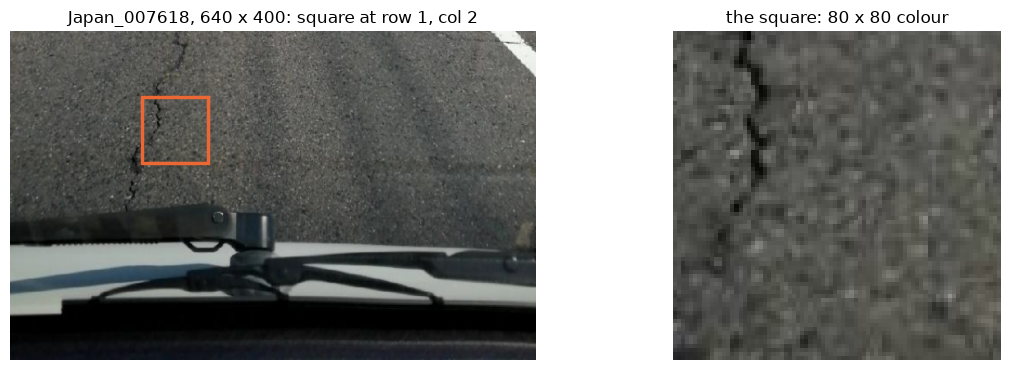

In [3]:
iid, row, col = examples["D00"]
frame = frame_of(iid)
sq = square_of(frame, row, col)
photo_mean = features.photo_brightness(frame)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [2.2, 1]})
axes[0].imshow(frame)
axes[0].add_patch(Rectangle((col * SQ, row * SQ), SQ, SQ, fill=False, edgecolor="#eb6834", linewidth=2.5))
axes[0].set_title(f"{iid}, 640 x 400: square at row {row}, col {col}")
axes[1].imshow(sq)
axes[1].set_title("the square: 80 x 80 colour")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

## Step 1: colour → grayscale

**Why:** damage is about **shape, edges and darkness**, not colour. Asphalt is a different colour in every country, light and camera. Grayscale keeps the brightness and drops the colour: each pixel goes from 3 numbers (red, green, blue) to **1** (brightness). Edge detection only needs brightness anyway.

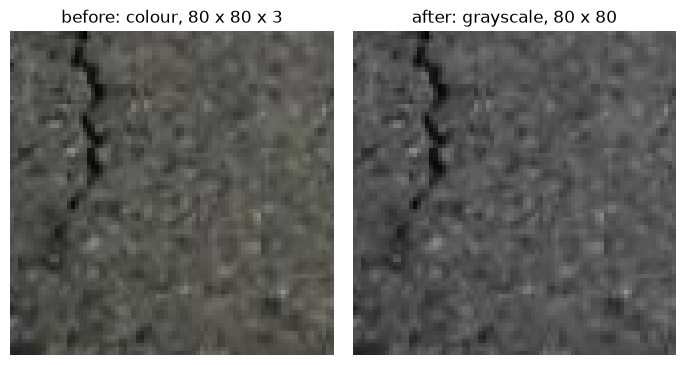

In [4]:
gray80 = np.asarray(sq.convert("L"), dtype=float) / 255

fig, axes = plt.subplots(1, 2, figsize=(7, 3.6))
axes[0].imshow(sq)
axes[0].set_title("before: colour, 80 x 80 x 3")
axes[1].imshow(gray80, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("after: grayscale, 80 x 80")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

## Step 2: resize 80 × 80 → 64 × 64

This is a **second** resize, of one square only (the first one made the whole photo 640 × 400). Brightness is also scaled to 0–1.

**Why 64:**
1. **The HOG grid fits exactly:** cells are 8 × 8 px, and 64 ÷ 8 = 8, a clean **8 × 8 grid of cells** (orange lines).
2. **Less work:** 4,096 pixels instead of 6,400 (36% fewer), and fewer HOG numbers.

**Is 80 wrong?** No. 80 ÷ 8 = 10 also fits, giving 10 × 10 cells → 9 × 9 blocks × 36 = 2,916 numbers instead of 1,764. **The trade-off:** shrinking can blur very thin cracks. 64 is a **design choice** for speed, not a requirement; if thin cracks get missed later, trying 80 is a fair experiment.

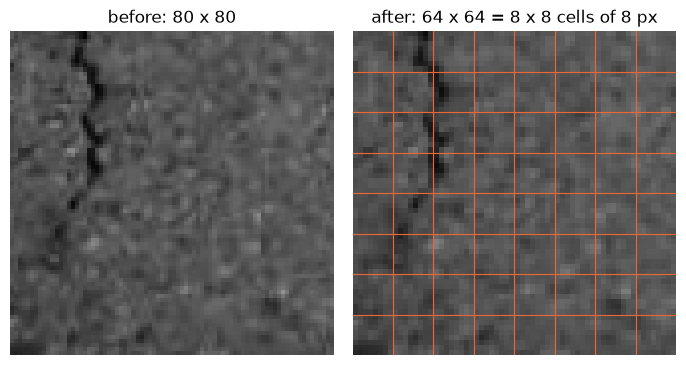

In [5]:
g = features.gray64(sq)  # steps 1 + 2 together, exactly as extract() does it

fig, axes = plt.subplots(1, 2, figsize=(7, 3.6))
axes[0].imshow(gray80, cmap="gray", vmin=0, vmax=1)
axes[0].set_title("before: 80 x 80")
axes[1].imshow(g, cmap="gray", vmin=0, vmax=1)
for k in range(1, 8):
    axes[1].axhline(k * 8 - 0.5, color="#eb6834", linewidth=0.8)
    axes[1].axvline(k * 8 - 0.5, color="#eb6834", linewidth=0.8)
axes[1].set_title("after: 64 x 64 = 8 x 8 cells of 8 px")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

## Step 3: HOG (Histogram of Oriented Gradients): 1,764 numbers

**For every pixel**, HOG measures two things about the brightness change around it (its *gradient*):
- **magnitude:** how strong the change is (a dark crack on light asphalt = strong);
- **direction:** which way it changes, folded into 0°–180°.

**Per 8 × 8 cell**, the directions are sorted into **9 bins of 20°**: 0°, 20°, …, 160°. Each pixel adds its **strength** to its bin, so a bin is not a pixel count: a few strong crack pixels outweigh many faint grain pixels.
- A **vertical** crack (along the road, D00): brightness changes left ↔ right → its pixels vote near **0°**.
- A **horizontal** crack (across the road, D10): brightness changes up ↕ down → votes near **90°**.

**Why cells, not one histogram for the whole square:** cells keep **where** the edges are. "Crack edges in the left column, clean asphalt on the right" is different from "edges everywhere", and one big histogram could not tell them apart.

**Why blocks:** neighbouring cells are grouped into **2 × 2 blocks** and normalised together, so a shadow or bright sun does not change the numbers much; only the *pattern* counts. The block slides one cell at a time and overlaps:
- positions across: 8 − 2 + 1 = **7**; down: **7** → **49 blocks**
- each block: 4 cells × 9 bins = **36 numbers**
- **49 × 36 = 1,764 numbers**

In the pictures below: the **middle** one draws each cell as little lines along the edges it found (brighter = stronger); the **right** one is the 9 bins of the single strongest cell.

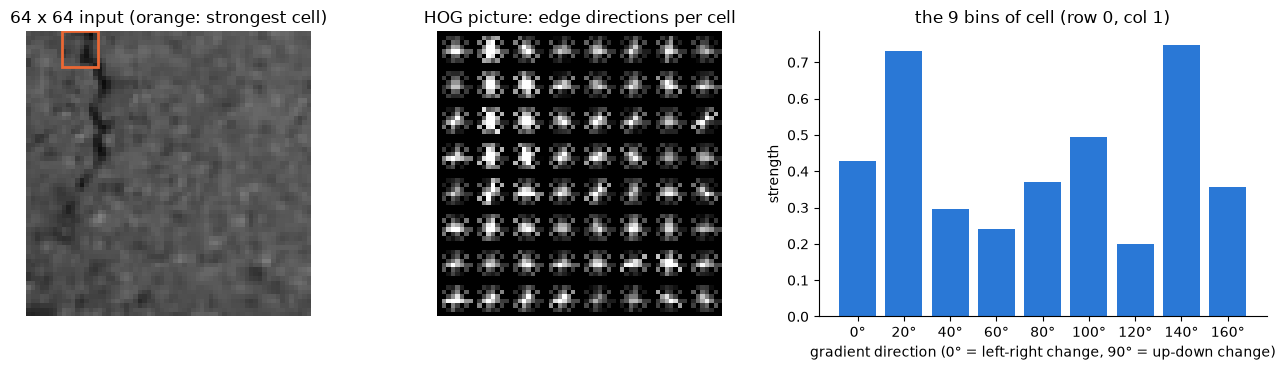

HOG numbers: 1764  (= 7 x 7 blocks x 2 x 2 cells x 9 bins = 1764)


In [6]:
h, hog_img = hog(g, orientations=features.ORIENTATIONS, pixels_per_cell=features.CELL,
                 cells_per_block=features.BLOCK, visualize=True)
# the raw 9-bin histogram of each cell (before block normalisation), only to show one cell:
# every pixel votes for its gradient direction, with a weight = how strong its gradient is
gr, gc = np.gradient(g)
mag, ang = np.hypot(gr, gc), np.rad2deg(np.arctan2(gr, gc)) % 180
bins = (ang // 20).astype(int).clip(0, 8)
cells = np.zeros((8, 8, 9))
for i in range(64):
    for j in range(64):
        cells[i // 8, j // 8, bins[i, j]] += mag[i, j]
cr, cc = np.unravel_index(cells.sum(axis=2).argmax(), (8, 8))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1, 1, 1.3]})
axes[0].imshow(g, cmap="gray", vmin=0, vmax=1)
axes[0].add_patch(Rectangle((cc * 8 - 0.5, cr * 8 - 0.5), 8, 8, fill=False, edgecolor="#eb6834", linewidth=2))
axes[0].set_title("64 x 64 input (orange: strongest cell)")
axes[1].imshow(rescale_intensity(hog_img, in_range=(0, hog_img.max() / 2)), cmap="gray")
axes[1].set_title("HOG picture: edge directions per cell")
for ax in axes[:2]:
    ax.axis("off")
axes[2].bar(np.arange(9) * 20, cells[cr, cc], width=16, color="#2a78d6")
axes[2].set_xticks(np.arange(9) * 20, [f"{d}°" for d in range(0, 180, 20)])
axes[2].set_xlabel("gradient direction (0° = left-right change, 90° = up-down change)")
axes[2].set_ylabel("strength")
axes[2].set_title(f"the 9 bins of cell (row {cr}, col {cc})")
axes[2].spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()
print(f"HOG numbers: {len(h)}  (= 7 x 7 blocks x 2 x 2 cells x 9 bins = {7 * 7 * 2 * 2 * 9})")

## Step 4: 5 simple measures

HOG is detailed but "blind" to some plain facts. These 5 numbers each answer one simple question about the same 64 × 64 square:

| Measure | Question | How | Example | Useful for |
|---|---|---|---|---|
| **dark share** | how much of it is unusually dark? | share of pixels at least 0.12 darker than the **whole photo's** average | 0.43 = 43% of the pixels are dark | potholes, deep cracks |
| **edge density** | how busy is it? | share of pixels that the **Canny** edge detector marks as an edge | 0.30 = 30% of the pixels are edges | alligator cracks (many edges) |
| **gx share** | how much change runs left ↔ right? | sum of horizontal gradient strengths ÷ (horizontal + vertical) | 0.70 = mostly vertical lines | longitudinal cracks |
| **gy share** | how much change runs up ↕ down? | sum of vertical gradient strengths ÷ (horizontal + vertical) | 0.70 = mostly horizontal lines | transverse cracks |
| **contrast** | how different are light and dark? | standard deviation of the brightness | higher = more varied surface | damage vs smooth road |

gx share + gy share = 1, so together they say which way the lines in the square mostly run. (Dark share uses the *photo's* average, not the square's, so a square that is entirely a dark pothole still counts as dark.)

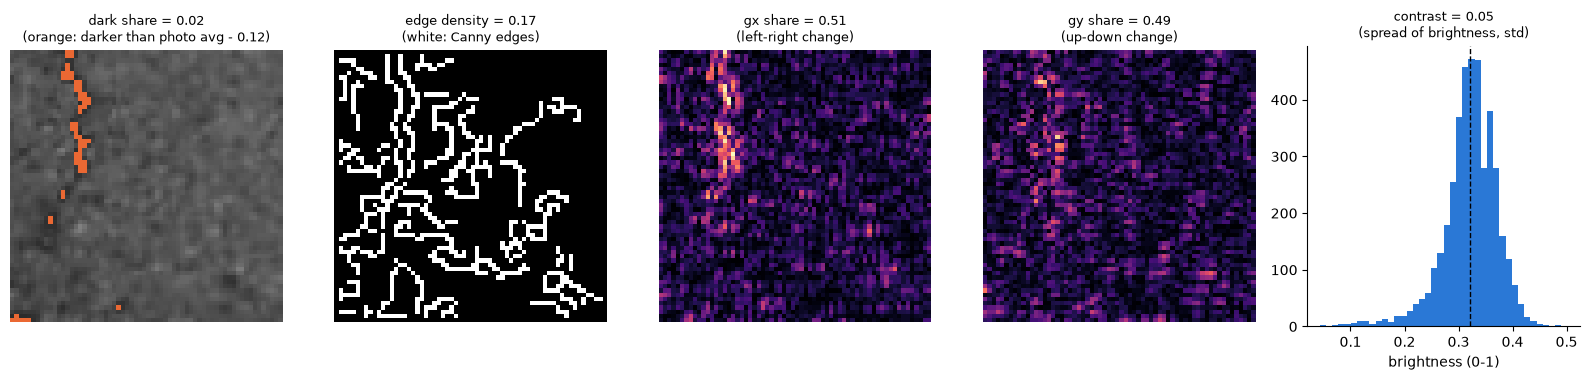

In [7]:
gy, gx = np.gradient(g)
dark = g < photo_mean - features.DARK_BELOW
edges = canny(g)
vals = dict(zip(features.SIMPLE, features.simple_measures(g, photo_mean)))

fig, axes = plt.subplots(1, 5, figsize=(16, 3.9))
overlay = np.dstack([g, g, g])
overlay[dark] = [0.92, 0.41, 0.2]
panels = [
    (overlay, None, f"dark share = {vals['dark_share']:.2f}\n(orange: darker than photo avg - 0.12)"),
    (edges, "gray", f"edge density = {vals['edge_density']:.2f}\n(white: Canny edges)"),
    (np.abs(gx), "magma", f"gx share = {vals['gx_share']:.2f}\n(left-right change)"),
    (np.abs(gy), "magma", f"gy share = {vals['gy_share']:.2f}\n(up-down change)"),
]
for ax, (img, cmap, title) in zip(axes, panels):
    ax.imshow(img, cmap=cmap, vmin=0, vmax=None if cmap == "magma" else 1)
    ax.set_title(title, fontsize=9)
    ax.axis("off")
axes[2].images[0].set_clim(0, max(np.abs(gx).max(), np.abs(gy).max()))
axes[3].images[0].set_clim(0, max(np.abs(gx).max(), np.abs(gy).max()))
axes[4].hist(g.ravel(), bins=40, color="#2a78d6")
axes[4].axvline(g.mean(), color="black", linestyle="--", linewidth=1)
axes[4].set_title(f"contrast = {vals['contrast']:.2f}\n(spread of brightness, std)", fontsize=9)
axes[4].set_xlabel("brightness (0-1)")
axes[4].spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## Step 5: join everything into one row of 1,769 numbers

1,764 HOG numbers, then the 5 measures. This row is **all a model ever sees** of the square.

**How to read it:** you don't read the numbers one by one ("number 312 means pothole"). Each HOG number is "how strong edges of one direction are in one cell of one block". Together they describe the **visual structure** of the square: where the edges are, which way they run, how strong they are. The last 5 are the plain summaries from step 4.

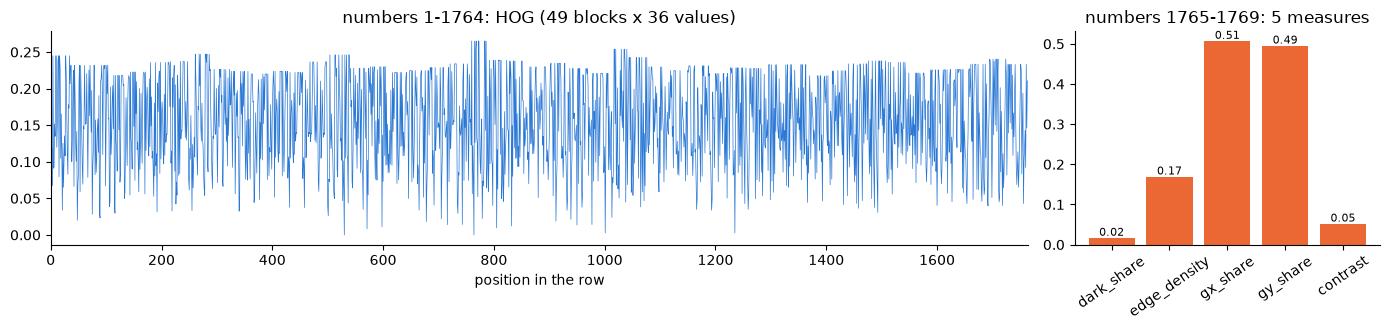

row length: 1769; first 5 HOG numbers: [0.198 0.056 0.119 0.067 0.245]; last 5: [0.015 0.168 0.506 0.494 0.051]


In [8]:
x = extract(sq, photo_mean)

fig, axes = plt.subplots(1, 2, figsize=(14, 3.4), gridspec_kw={"width_ratios": [3.2, 1]})
axes[0].plot(np.arange(features.N_HOG), x[:features.N_HOG], color="#2a78d6", linewidth=0.5)
axes[0].set_title(f"numbers 1-{features.N_HOG}: HOG (49 blocks x 36 values)")
axes[0].set_xlabel("position in the row")
axes[0].set_xlim(0, features.N_HOG)
bars = axes[1].bar(features.SIMPLE, x[features.N_HOG:], color="#eb6834")
axes[1].bar_label(bars, fmt="%.2f", fontsize=8)
axes[1].set_title(f"numbers {features.N_HOG + 1}-{features.N_FEATURES}: 5 measures")
axes[1].tick_params(axis="x", rotation=35)
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()
print(f"row length: {len(x)}; first 5 HOG numbers: {np.round(x[:5], 3)}; last 5: {np.round(x[-5:], 3)}")

### How a model uses these rows

**The 1,769 numbers are the description, not the label.**

- **Training:** a model (softmax, SVM, MLP) gets many pairs of *(1,769 numbers, correct label)* and learns which **combinations** of numbers go with which class. For example, a strong 0° pattern down one column of cells plus some dark share tends to mean D00.
- **Predicting:** a new square goes through **exactly the same** `extract()`. The model reads its 1,769 numbers and answers D00 / D10 / D20 / D40 / none.

That is why there must be one feature function for training and the app: if the app made the numbers even slightly differently, the model would be reading a description it was never taught.

## The same steps on one square of every class

Read across a row to follow one square through the steps; read down a column to compare classes. What to look for:
- **HOG:** D00 lines run **up-down**, D10 **left-right**, D20 every way (a net), `none` faint.
- **Dark / edges:** the pothole is mostly dark; alligator cracks have the most edges; clean road has few of either.

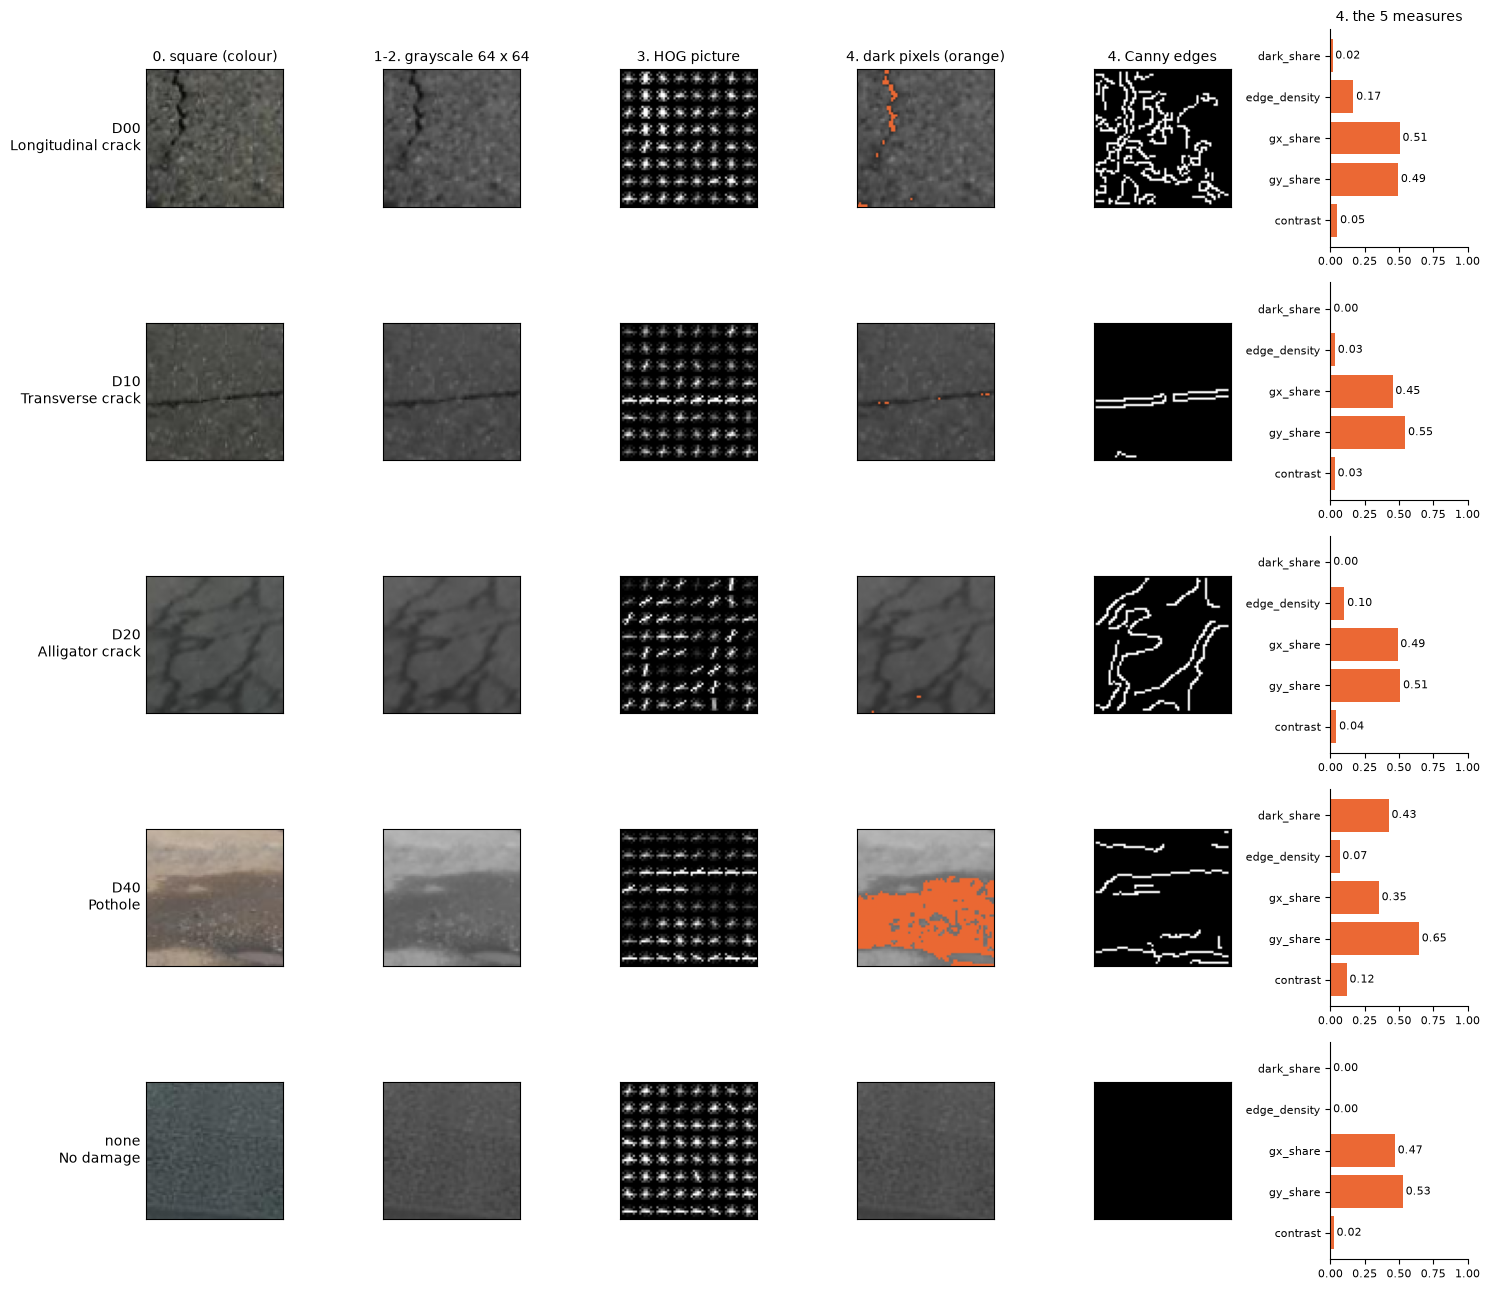

In [9]:
order = DAMAGE + ["none"]
fig, axes = plt.subplots(len(order), 6, figsize=(15, 13))
for r, cls in enumerate(order):
    iid, row, col = examples[cls]
    fr = frame_of(iid)
    s = square_of(fr, row, col)
    pm = features.photo_brightness(fr)
    g_ = features.gray64(s)
    _, hv = hog(g_, orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2), visualize=True)
    d = g_ < pm - features.DARK_BELOW
    ov = np.dstack([g_, g_, g_]); ov[d] = [0.92, 0.41, 0.2]
    v = extract(s, pm)[features.N_HOG:]
    axes[r, 0].imshow(s)
    axes[r, 1].imshow(g_, cmap="gray", vmin=0, vmax=1)
    axes[r, 2].imshow(rescale_intensity(hv, in_range=(0, hv.max() / 2)), cmap="gray")
    axes[r, 3].imshow(ov)
    axes[r, 4].imshow(canny(g_), cmap="gray")
    axes[r, 5].barh(features.SIMPLE[::-1], v[::-1], color="#eb6834")
    axes[r, 5].set_xlim(0, 1)
    for k, val in enumerate(v[::-1]):
        axes[r, 5].text(val + 0.02, k, f"{val:.2f}", va="center", fontsize=8)
    axes[r, 5].tick_params(labelsize=8)
    axes[r, 5].spines[["top", "right"]].set_visible(False)
    for ax in axes[r, :5]:
        ax.set_xticks([]); ax.set_yticks([])
    axes[r, 0].set_ylabel(NAMES[cls].replace(" · ", "\n"), rotation=0, ha="right", va="center", fontsize=10)
for ax, t in zip(axes[0], ["0. square (colour)", "1-2. grayscale 64 x 64", "3. HOG picture",
                           "4. dark pixels (orange)", "4. Canny edges", "4. the 5 measures"]):
    ax.set_title(t, fontsize=10)
plt.tight_layout()
plt.show()

## Checks (from the guide)

1. The output is always 1,769 long, with no NaN: tested on 1,000 real squares.
2. The same square always gives the same numbers.
3. Time 1,000 squares: expect a few milliseconds each.
4. The unit test `tests/test_features.py` (length, NaN, same input → same output, and a vertical line → mostly gx) passes.

In [10]:
sample = patches.drop_duplicates("image_id").sample(25, random_state=config.SEED).image_id
squares, means = [], []
for iid in sample:  # 25 photos x 40 squares = 1,000 real squares
    fr = frame_of(iid)
    pm = features.photo_brightness(fr)
    for r in range(config.IMG_H // SQ):
        for c in range(config.IMG_W // SQ):
            squares.append(square_of(fr, r, c)); means.append(pm)

t = time.perf_counter()
X = np.array([extract(s, pm) for s, pm in zip(squares, means)])
ms = (time.perf_counter() - t) / len(squares) * 1000

assert X.shape == (1000, features.N_FEATURES), X.shape
assert not np.isnan(X).any(), "NaN in features"
assert np.array_equal(extract(squares[0], means[0]), X[0]), "same square, different numbers"
print(f"OK: {X.shape[0]} squares x {X.shape[1]} numbers, no NaN, repeatable; {ms:.1f} ms per square",
      f"-> about {ms * 240_000 / 60_000:.0f} min for all 240,000 squares (Phase 9.2)")

OK: 1000 squares x 1769 numbers, no NaN, repeatable; 0.8 ms per square -> about 3 min for all 240,000 squares (Phase 9.2)


In [11]:
import subprocess

out = subprocess.run([sys.executable, "-m", "pytest", "-q", "--color=no", "-p", "no:cacheprovider", "tests/test_features.py"],
                     cwd=Path.cwd().parents[1], capture_output=True, text=True)
print(out.stdout.strip().splitlines()[-1])

3 passed in 0.21s


### Result (9.1)

**`extract(square, photo_mean)` is in `ml/features.py`** and turns one 80 × 80 square into **1,769 numbers** (1,764 HOG + 5 measures). All guide checks pass:
- 1,000 real squares: always 1,769 numbers, no NaN, the same square gives the same numbers.
- About **1 ms per square**, so all 240,000 squares take a few minutes (Phase 9.2).
- `tests/test_features.py`: 3 tests pass.

**What the pictures show** (on clear examples):
- **HOG sees direction:** the D00 crack lights up cells with lines running up and down, the D10 crack a band running left to right, the alligator net every direction, plain road only faint noise.
- **Dark share** fires on the pothole (0.43) and on the crack line itself; **edge density** is 0 on plain road and highest on the busy crack squares.

**Two weak spots to keep an eye on (checked properly in 9.3):**
- **gx / gy share stay close to 0.5 for every class.** The asphalt grain makes gradients in every direction, and a thin crack is only a few pixels of the square. We also tried smoothing first and counting only at Canny edges on 150 squares per class: none of them separated D00 from D10 by more than 0.03 on average. So we keep the guide's simple definition; HOG carries direction in far more detail.
- **Dark share depends on the whole photo.** A square in a shadow on an otherwise bright photo is "dark" without any damage. That is why `extract` takes `photo_mean`: the app must pass the average brightness of the uploaded photo, exactly as training does.

**Settings that are assumptions:** "much darker" = 0.12 below the photo average. HOG settings are the standard ones; the resize to 64 is a choice so the cells divide exactly.

# 9.2 Run it on every square, once

Loop over all 6,000 photos: open, crop and resize (Phase 6.1), cut the 40 squares, and run `extract()` on each, with the photo's average brightness. That is 240,000 rows of 1,769 numbers.

**How it is saved** (`data/processed/09_features/`):

| File | What | Why this way |
|---|---|---|
| `X.npy` | 240,000 × 1,769 numbers, `float32` | about **1.7 GB**. A `.npy` file can be *memory-mapped*: later phases read only the rows they need (e.g. the 46,408 balanced train rows) without loading all 1.7 GB. `float32` halves the size and is plenty precise for these numbers |
| `meta.npz` | `y`, `image_id`, `split`, `patch_id`, one per row | the guide's `features.npz` content, minus `X` |

**`y` is stored as integers 0–4** (`config.CLASS_TO_ID`): the MLP with early stopping crashes on text labels like "D00" in scikit-learn 1.7/1.8. Names come back via `config.ID_TO_CLASS`, only for charts and the app.

The photos are spread over all CPU cores (`joblib`). **If `X.npy` already exists it is loaded, not recomputed**: this runs once.

In [12]:
from joblib import Parallel, delayed
from tqdm.auto import tqdm

FEAT = config.PROCESSED / "09_features"
FEAT.mkdir(exist_ok=True)
ROWS, COLS = config.IMG_H // SQ, config.IMG_W // SQ   # 5 x 8 = 40 squares per photo

# rows must be photo by photo, 40 each, row-major: that is how we fill X below
order = patches[["image_id", "row", "col"]]
photo_ids = order.image_id.values[::40]
assert len(photo_ids) * 40 == len(order)
assert (order.row.values == np.tile(np.repeat(np.arange(ROWS), COLS), len(photo_ids))).all()
assert (order.col.values == np.tile(np.arange(COLS), ROWS * len(photo_ids))).all()
assert (order.image_id.values == np.repeat(photo_ids, 40)).all()


def photo_features(image_id):
    """All 40 squares of one photo -> (40, 1769) float32, in row-major order."""
    frame = frame_of(image_id)
    pm = features.photo_brightness(frame)
    return np.stack([extract(square_of(frame, r, c), pm) for r in range(ROWS) for c in range(COLS)]).astype(np.float32)


x_path = FEAT / "X.npy"
if x_path.exists():
    print("X.npy already exists: loading it, not recomputing")
else:
    X = np.lib.format.open_memmap(x_path, mode="w+", dtype=np.float32, shape=(len(order), features.N_FEATURES))
    chunk = 240                                                      # photos per batch (= 9,600 rows)
    t0 = time.perf_counter()
    for s in tqdm(range(0, len(photo_ids), chunk), desc="batches of 240 photos"):
        ids = photo_ids[s:s + chunk]
        out = Parallel(n_jobs=-1)(delayed(photo_features)(i) for i in ids)
        X[s * 40:(s + len(ids)) * 40] = np.concatenate(out)
    X.flush()
    del X
    print(f"done in {(time.perf_counter() - t0) / 60:.1f} min")

np.savez(FEAT / "meta.npz",
         y=patches.label.map(config.CLASS_TO_ID).values.astype(np.int8),
         image_id=patches.image_id.values, split=patches.split.values,
         patch_id=(patches.image_id + "_r" + patches.row.astype(str) + "_c" + patches.col.astype(str)).values)

X.npy already exists: loading it, not recomputing


**Check:** the file has one row per square, 1,769 columns, no NaN, labels are 0–4, and a few random rows match a fresh `extract()` of the same square (so rows and squares line up).

In [13]:
X = np.load(FEAT / "X.npy", mmap_mode="r")         # read from disk on demand, not all into memory
meta = np.load(FEAT / "meta.npz", allow_pickle=True)
y, split = meta["y"], meta["split"]

assert X.shape == (len(patches), features.N_FEATURES), X.shape
assert not np.isnan(X[::97]).any()                   # every 97th row: fast, still 2,475 rows
assert set(np.unique(y)) == set(range(5))
rng = np.random.default_rng(config.SEED)
for i in rng.choice(len(patches), 5, replace=False):
    iid, r, c = patches.image_id[i], patches.row[i], patches.col[i]
    fr = frame_of(iid)
    assert np.allclose(X[i], extract(square_of(fr, r, c), features.photo_brightness(fr)), atol=1e-5), i

print(f"X: {X.shape[0]:,} rows x {X.shape[1]:,} numbers, {x_path.stat().st_size / 1e9:.2f} GB on disk")
pd.crosstab(pd.Series(y).map(config.ID_TO_CLASS).rename("label"), pd.Series(split, name="split"))[["train", "val", "test"]]

X: 240,000 rows x 1,769 numbers, 1.70 GB on disk


split,train,val,test
label,,,
D00,3231,743,790
D10,1819,323,353
D20,13076,2915,2469
D40,2130,413,360
none,147744,31606,32028


# 9.3 Sanity check: do the features carry signal?

Before training anything: if the numbers look the same for every class, no model can learn from them. Two checks from the guide, on the **train** split only (val and test stay unseen):

1. **The 5 simple measures by class** (box plots). Expectation: **edge density** and **dark share** clearly higher for potholes (D40) and alligator cracks (D20) than for `none`.
2. **HOG by class.** Expectation: longitudinal (D00) and transverse (D10) cracks show **different main directions**.

If every class looks the same, first check that labels and squares line up (Phase 6) before blaming the features.

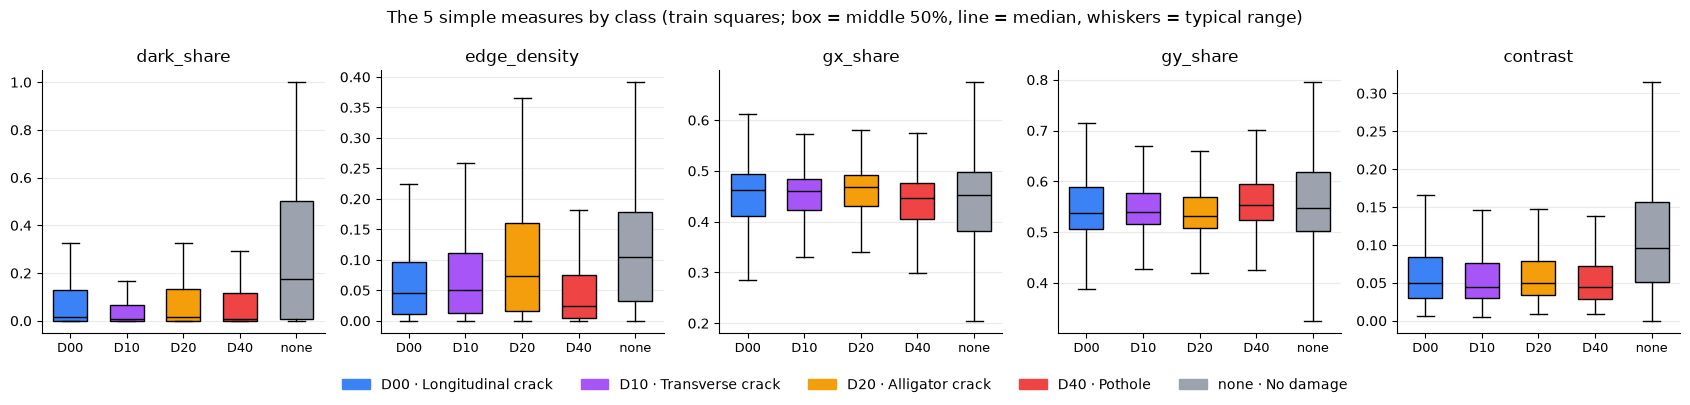

In [14]:
LABELS = config.CLASSES
COLORS = {"D00": "#3b82f6", "D10": "#a855f7", "D20": "#f59e0b", "D40": "#ef4444", "none": "#9ca3af"}
tr = np.where(split == "train")[0]
simple = pd.DataFrame(X[tr, features.N_HOG:], columns=features.SIMPLE)
simple["label"] = pd.Series(y[tr]).map(config.ID_TO_CLASS).values

fig, axes = plt.subplots(1, 5, figsize=(17, 4))
for ax, m in zip(axes, features.SIMPLE):
    data = [simple.loc[simple.label == k, m] for k in LABELS]
    bp = ax.boxplot(data, showfliers=False, patch_artist=True, widths=0.6, medianprops={"color": "black"})
    for box, k in zip(bp["boxes"], LABELS):
        box.set_facecolor(COLORS[k])
    ax.set_xticks(range(1, 6), LABELS, fontsize=9)
    ax.set_title(m)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.25)
fig.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=COLORS[k], label=NAMES[k]) for k in LABELS],
           loc="lower center", ncol=5, frameon=False)
plt.suptitle("The 5 simple measures by class (train squares; box = middle 50%, line = median, whiskers = typical range)")
plt.tight_layout(rect=(0, 0.08, 1, 1))
plt.show()

The same as numbers: the **median** of each measure per class. `none` is the reference; a useful measure moves away from it for the damage classes.

In [15]:
med = simple.groupby("label")[features.SIMPLE].median().reindex(LABELS)
med.rename(index=NAMES).round(3)

,dark_share,edge_density,gx_share,gy_share,contrast
label,,,,,
D00 · Longitudinal crack,0.017,0.046,0.463,0.537,0.050
D10 · Transverse crack,0.008,0.050,0.461,0.539,0.045
D20 · Alligator crack,0.016,0.073,0.468,0.532,0.050
D40 · Pothole,0.009,0.025,0.446,0.554,0.044
none · No damage,0.174,0.105,0.453,0.547,0.096


### HOG by class

**a) The average direction profile.** Each HOG number belongs to one of the 9 direction bins (every 9th number is the same bin). Averaging all of a class's train squares per bin gives that class's typical **mix of edge directions**. Shown as each class's difference from `none`, because the asphalt grain is the same everywhere and would hide the differences.

Reminder: **0° = brightness changes left ↔ right = a vertical line** (along the road, D00); **90° = up ↕ down = a horizontal line** (across the road, D10).

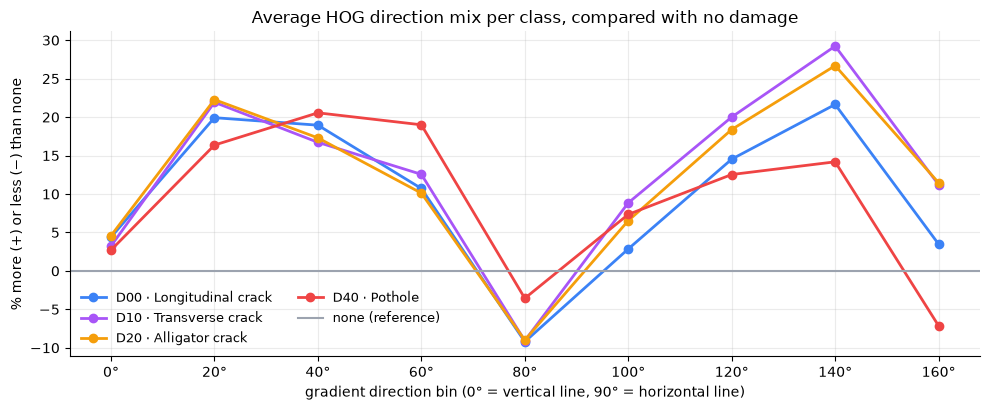

In [16]:
hog_tr = np.asarray(X[tr, :features.N_HOG])
profile = pd.DataFrame(hog_tr.reshape(len(tr), -1, 9).mean(axis=1), columns=[f"{d}°" for d in range(0, 180, 20)])
profile["label"] = simple.label.values
prof = profile.groupby("label").mean().reindex(LABELS)
diff = (prof - prof.loc["none"]) / prof.loc["none"] * 100     # % difference from none

fig, ax = plt.subplots(figsize=(10, 4.2))
xs = np.arange(9)
for k in ["D00", "D10", "D20", "D40"]:
    ax.plot(xs, diff.loc[k], marker="o", linewidth=2, color=COLORS[k], label=NAMES[k])
ax.axhline(0, color=COLORS["none"], linewidth=1.5, label="none (reference)")
ax.set_xticks(xs, prof.columns)
ax.set_xlabel("gradient direction bin (0° = vertical line, 90° = horizontal line)")
ax.set_ylabel("% more (+) or less (−) than none")
ax.set_title("Average HOG direction mix per class, compared with no damage")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(alpha=0.25)
ax.legend(frameon=False, fontsize=9, ncol=2)
plt.tight_layout()
plt.show()

**b) One HOG picture per class**, from a **random** train square of each class (seed 42), not hand-picked like in 9.1. This is what typical squares look like to HOG.

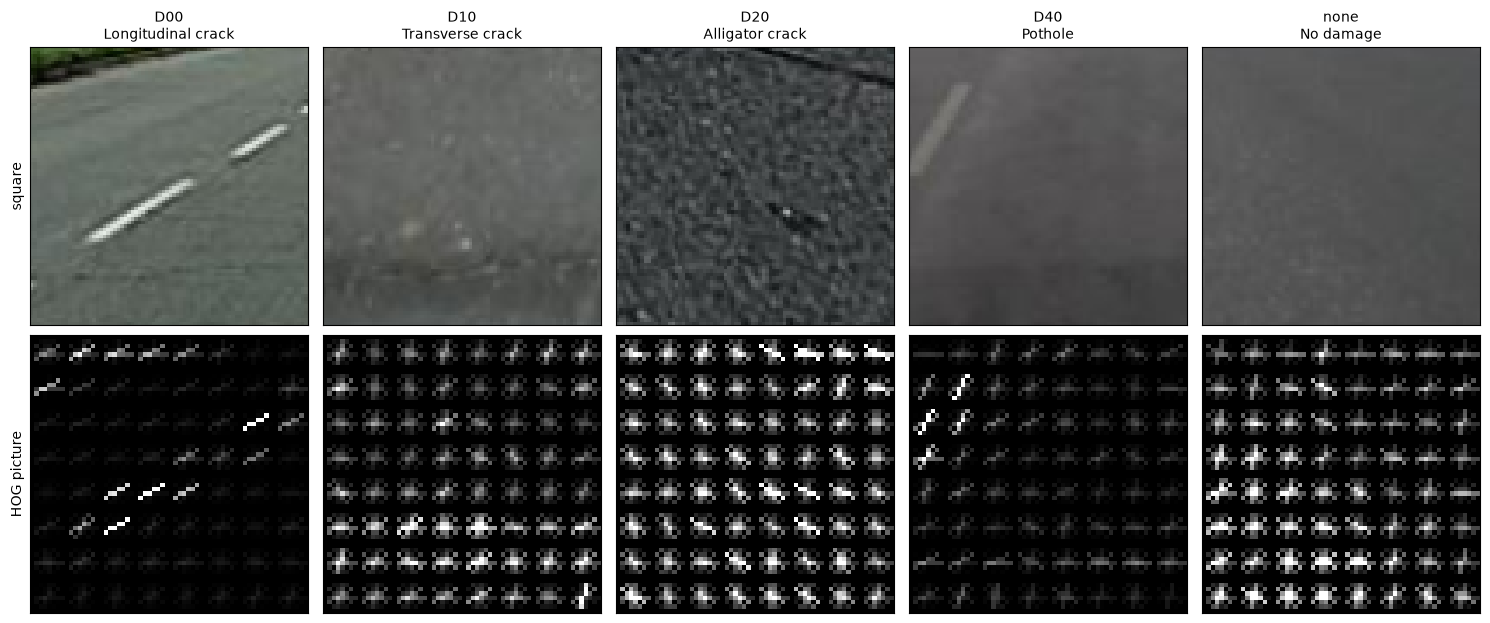

In [17]:
rng = np.random.default_rng(config.SEED)
fig, axes = plt.subplots(2, 5, figsize=(15, 6.4))
for j, k in enumerate(LABELS):
    i = rng.choice(tr[y[tr] == config.CLASS_TO_ID[k]])
    fr = frame_of(patches.image_id[i])
    s = square_of(fr, patches.row[i], patches.col[i])
    _, hv = hog(features.gray64(s), orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2), visualize=True)
    axes[0, j].imshow(s)
    axes[0, j].set_title(NAMES[k].replace(" · ", "\n"), fontsize=10)
    axes[1, j].imshow(rescale_intensity(hv, in_range=(0, hv.max() / 2)), cmap="gray")
    for ax in axes[:, j]:
        ax.set_xticks([]); ax.set_yticks([])
axes[0, 0].set_ylabel("square")
axes[1, 0].set_ylabel("HOG picture")
plt.tight_layout()
plt.show()

### Why is `none` the busiest class? Look at where the squares sit

The box plots show the **opposite** of the guide's expectation: `none` has the highest dark share, edge density and contrast. Labels and squares do line up (checked in 9.2 and in the Phase 6 PNGs), so we look at **where in the photo** each class sits (row 0 = top of the 640 × 400 frame, row 4 = bottom).

In [18]:
pos = patches.iloc[tr][["row", "col"]].reset_index(drop=True)
by_row = pd.crosstab(pos.row, simple.label, normalize="columns").reindex(columns=LABELS) * 100
none_row = simple[simple.label == "none"].groupby(pos.row[simple.label == "none"])[["dark_share", "edge_density", "contrast"]].median()
display(by_row.round(1).rename(columns=NAMES).rename_axis("row (% of each class)"))
display(none_row.round(3).rename_axis("row (none only, median)"))

middle = (pos.row <= 3) & pos.col.between(1, 6)   # leave out the bottom row and the side columns
simple[middle.values].groupby("label")[["dark_share", "edge_density", "contrast"]].median().reindex(LABELS).rename(index=NAMES).round(3)

label,D00 · Longitudinal crack,D10 · Transverse crack,D20 · Alligator crack,D40 · Pothole,none · No damage
row (% of each class),,,,,
0,3.3,3.2,4.1,3.2,22.2
1,8.3,7.6,11.1,9.9,21.3
2,31.2,26.9,27.0,29.2,18.9
3,40.3,46.5,32.0,35.6,17.9
4,16.9,15.7,25.8,22.2,19.6


,dark_share,edge_density,contrast
"row (none only, median)",,,
0,0.099,0.129,0.148
1,0.281,0.162,0.146
2,0.103,0.093,0.086
3,0.041,0.035,0.049
4,0.518,0.095,0.081


,dark_share,edge_density,contrast
label,,,
D00 · Longitudinal crack,0.011,0.042,0.050
D10 · Transverse crack,0.004,0.044,0.042
D20 · Alligator crack,0.006,0.065,0.048
D40 · Pothole,0.002,0.025,0.042
none · No damage,0.093,0.102,0.104


### Findings (9.2 and 9.3)

**9.2: done.** All 240,000 squares extracted in **0.7 min** on 12 cores (much faster than the guide's "tens of minutes"). Saved `09_features/X.npy` (240,000 × 1,769, float32, 1.70 GB, memory-mappable) and `meta.npz` (`y` as 0–4, `image_id`, `split`, `patch_id`). Checks pass: right shape, no NaN, labels 0–4, and 5 random rows equal a fresh `extract()` of the same square, so rows and squares line up.

**9.3: the features do carry signal, but not the one the guide expected.**

1. **`none` is the busiest class, not the calmest.** Median edge density 0.105 vs 0.025–0.073 for damage; dark share 0.174 vs ≤ 0.017; contrast 0.096 vs ≤ 0.050. The guide expected potholes and alligator cracks to be higher than `none`.
2. **Why:** `none` means *everything that is not labelled damage*, not just clean asphalt. It is spread evenly over all rows, including the top rows (cars, buildings, roadside: busy) and the bottom row (often the dark car bonnet: median dark share **0.52**). Damage sits mostly in rows 2–3, on plain asphalt. Even in the middle of the road `none` stays busier, because lane markings, kerbs and patches count as `none` too.
3. **Among the damage classes the expectations partly hold:** alligator cracks (D20) have the most edges (0.073). Potholes (D40) are *not* darker: many are pale, dusty patches on Indian roads, and the random example above shows how loose a pothole box can be.
4. **HOG directions:** all damage classes have more diagonal edges (20–60°, 120–160°) and fewer horizontal ones (80°) than `none`. **D00 and D10 look almost the same**, not "vertical vs horizontal": in a photo taken down the road, perspective turns most cracks diagonal. HOG still sees direction per cell (the 9.1 examples), but the class averages barely differ.

**What this means for training (Phase 10+):**
- The models will have an easy job telling "plain asphalt" from "busy scene", and a hard one telling damage from clean asphalt, and D00 from D10. **Expect confusion between D00 and D10**, and some `none` mistakes on clean road.
- There is a risk of a **shortcut**: "plain asphalt in the middle rows = damage". The confusion matrix on val will show whether that happens.
- Nothing to fix before training: the numbers do differ between classes, which is what 9.3 checks. If val results are poor, options are features that compare a square with **its own surroundings** rather than the whole photo, or leaving the bottom row (bonnet) out.